# Recunoasterea tipurilor de nori (CCSN): incarcarea si pre-procesarea datelor

Acest notebook pregateste setul de date CCSN pentru antrenare:

1. gaseste imaginile si clasele din folderul setului de date si verifica daca se pot deschide;
2. imparte setul, stratificat pe clase, in **train / val / test = 70% / 15% / 15%** si salveaza impartirea intr-un fisier CSV, ca sa fie aceeasi la fiecare rulare;
3. defineste transformarile: redimensionare la 224x224, normalizare cu media si deviatia standard ImageNet, augmentari doar pe train;
4. defineste clasa `CCSNDataset` (un `torch.utils.data.Dataset`) si construieste cele 3 `DataLoader`-e;
5. verifica functionarea: dimensiunile batch-urilor, etichetele, determinismul transformarilor de evaluare si o trecere completa prin toate imaginile.

**Setul de date:** CCSN (Cirrus Cumulus Stratus Nimbus), 11 clase de nori, imagini JPEG de 256x256, licenta CC0. Se descarca de pe [Harvard Dataverse](https://doi.org/10.7910/DVN/CADDPD) si se dezarhiveaza.

## 0. Configurare
- `DATA_DIR`: folderul dezarhivat al setului de date (cel care contine cate un subfolder pentru fiecare clasa, sau un folder parinte al acestuia).
- `SPLIT_FILE`: fisierul CSV cu impartirea. Daca exista, este citit; daca nu, este creat. Fisierul **se pune in repository**, ca impartirea sa fie aceeasi pentru toate experimentele.
- `NUM_WORKERS`: pe macOS, procesele auxiliare ale `DataLoader`-ului nu pot folosi clase definite intr-un notebook, deci folosim 0. Pe Linux / Colab folosim 2.

In [ ]:
import os
import platform
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

DATA_DIR = './CCSN_v2'
SPLIT_FILE = './splits/ccsn_splits.csv'
SEED = 42
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0 if platform.system() == 'Darwin' else 2
IMG_EXTENSIONS = ('.jpg', '.jpeg', '.png')

# Media si deviatia standard ImageNet: modelul (ResNet-18) este pre-antrenat pe ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Numele complete ale claselor, doar pentru afisare
CLOUD_NAMES = {'Ac': 'Altocumulus', 'As': 'Altostratus', 'Cb': 'Cumulonimbus', 'Cc': 'Cirrocumulus',
               'Ci': 'Cirrus', 'Cs': 'Cirrostratus', 'Ct': 'Contrails', 'Cu': 'Cumulus',
               'Ns': 'Nimbostratus', 'Sc': 'Stratocumulus', 'St': 'Stratus'}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('torch', torch.__version__, '| device:', device, '| num_workers:', NUM_WORKERS)

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


torch 2.12.0 | device: mps | num_workers: 0


## 1. Gasirea imaginilor si a claselor
Arhiva poate avea un folder in plus deasupra claselor (de exemplu `CCSN_v2/CCSN_v2/Ac/...`). Functia `find_class_root` coboara in structura de foldere pana gaseste folderul ale carui subfoldere contin imagini. Fiecare subfolder este o clasa, iar numele lui este eticheta.

In [2]:
def is_image(name):
    return name.lower().endswith(IMG_EXTENSIONS)


def find_class_root(root):
    # Primul folder (in latime) ale carui subfoldere contin direct imagini
    queue = [root]
    while queue:
        folder = queue.pop(0)
        subdirs = sorted(d for d in os.listdir(folder) if os.path.isdir(os.path.join(folder, d)) and not d.startswith('.'))
        with_images = [d for d in subdirs if any(is_image(f) for f in os.listdir(os.path.join(folder, d)))]
        if len(with_images) >= 2:
            return folder
        queue += [os.path.join(folder, d) for d in subdirs]
    raise FileNotFoundError('Nu am gasit foldere de clase cu imagini in ' + root)


def list_images(class_root):
    # Un tabel cu calea relativa si clasa fiecarei imagini
    rows = []
    for cls in sorted(os.listdir(class_root)):
        folder = os.path.join(class_root, cls)
        if not os.path.isdir(folder) or cls.startswith('.'):
            continue
        for f in sorted(os.listdir(folder)):
            if is_image(f) and not f.startswith('.'):
                rows.append({'path': os.path.join(cls, f), 'label': cls})
    return pd.DataFrame(rows)


assert os.path.isdir(DATA_DIR), 'Descarcati CCSN si dezarhivati-l in ' + DATA_DIR
CLASS_ROOT = find_class_root(DATA_DIR)
images = list_images(CLASS_ROOT)
CLASSES = sorted(images['label'].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
print('Folderul claselor:', CLASS_ROOT)
print('{} imagini, {} clase: {}'.format(len(images), len(CLASSES), CLASSES))

Folderul claselor: /Users/mutumihaela/Desktop/master/CV3/CCSN_v2
2543 imagini, 11 clase: ['Ac', 'As', 'Cb', 'Cc', 'Ci', 'Cs', 'Ct', 'Cu', 'Ns', 'Sc', 'St']


## 2. Verificarea imaginilor
Deschidem fiecare imagine o data, ca sa aflam dimensiunile si modul de culoare si sa eliminam fisierele care nu se pot citi. Asa, o imagine corupta nu opreste antrenarea la mijlocul unei epoci. La final afisam cate imagini are fiecare clasa: clasele nu sunt echilibrate, deci impartirea trebuie sa fie stratificata.

Dimensiuni (latime x inaltime): {(400, 400): 2332, (256, 256): 211}
Moduri de culoare: {'RGB': 2543}
Fisiere care nu se pot citi: 0
Imagini folosite: 2543


,clasa,imagini
Sc,Stratocumulus,340
Cs,Cirrostratus,287
Ns,Nimbostratus,274
Cc,Cirrocumulus,268
Cb,Cumulonimbus,242
Ac,Altocumulus,221
St,Stratus,202
Ct,Contrails,200
As,Altostratus,188
Cu,Cumulus,182


Raport intre cea mai mare si cea mai mica clasa: 2.45


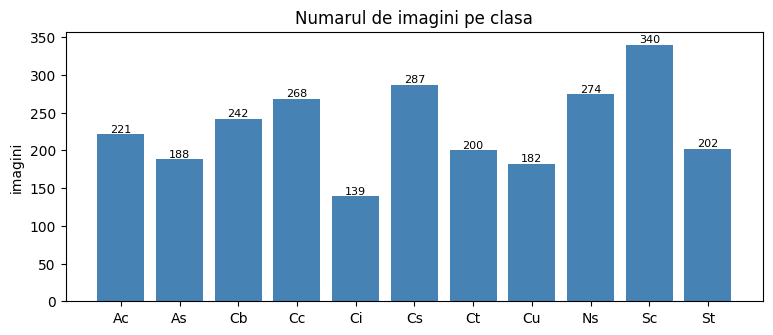

In [3]:
sizes, modes, broken = Counter(), Counter(), []
for rel in images['path']:
    try:
        with Image.open(os.path.join(CLASS_ROOT, rel)) as img:
            img.load()
            sizes[img.size] += 1
            modes[img.mode] += 1
    except Exception as e:
        broken.append((rel, str(e)))

print('Dimensiuni (latime x inaltime):', dict(sizes.most_common(5)))
print('Moduri de culoare:', dict(modes))
print('Fisiere care nu se pot citi:', len(broken))
for rel, err in broken:
    print('  ', rel, '->', err)
images = images[~images['path'].isin([rel for rel, _ in broken])].reset_index(drop=True)
print('Imagini folosite:', len(images))

# Distributia claselor, dupa eliminarea fisierelor care nu se pot citi
counts = images['label'].value_counts().reindex(CLASSES)
summary = pd.DataFrame({'clasa': [CLOUD_NAMES.get(c, c) for c in CLASSES], 'imagini': counts.values}, index=CLASSES)
display(summary.sort_values('imagini', ascending=False))
print('Raport intre cea mai mare si cea mai mica clasa: {:.2f}'.format(counts.max() / counts.min()))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(CLASSES, counts.values, color='steelblue')
ax.set_ylabel('imagini')
ax.set_title('Numarul de imagini pe clasa')
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha='center', fontsize=8)
plt.show()

## 3. Impartirea train / val / test
Setul de date nu vine impartit. Il impartim **stratificat** (fiecare clasa are aceeasi proportie in toate cele 3 split-uri), in doi pasi, cu `train_test_split` din scikit-learn:
1. punem deoparte 15% pentru test;
2. din rest, punem deoparte pentru validare o fractiune egala cu 15% din tot setul (15 / 85 din rest).

Proportia 70 / 15 / 15 lasa aproximativ 20-50 de imagini pe clasa in val si in test. Este putin, dar setul are doar ~2.500 de imagini; un split de test mai mare ar lasa prea putine imagini de antrenare pentru clasele mici (Ci).

Impartirea se salveaza in `SPLIT_FILE`. La rularile urmatoare este citita din fisier, deci este aceeasi pentru toate experimentele (cu si fara augmentare generativa).

In [4]:
def make_splits(df, val_fraction, test_fraction, seed):
    rest, test = train_test_split(df, test_size=test_fraction, stratify=df['label'], random_state=seed)
    train, val = train_test_split(rest, test_size=val_fraction / (1 - test_fraction), stratify=rest['label'], random_state=seed)
    return pd.concat([train.assign(split='train'), val.assign(split='val'), test.assign(split='test')]).reset_index(drop=True)


if os.path.exists(SPLIT_FILE):
    splits = pd.read_csv(SPLIT_FILE)
    print('Impartire citita din', SPLIT_FILE)
    missing = set(splits['path']) - set(images['path'])
    assert not missing, '{} imagini din {} lipsesc din DATA_DIR'.format(len(missing), SPLIT_FILE)
else:
    splits = make_splits(images, VAL_FRACTION, TEST_FRACTION, SEED)
    os.makedirs(os.path.dirname(SPLIT_FILE), exist_ok=True)
    splits.to_csv(SPLIT_FILE, index=False)
    print('Impartire noua, salvata in', SPLIT_FILE)

# Verificari: fiecare imagine apare o singura data, in exact un split
assert splits['path'].is_unique, 'aceeasi imagine apare in mai multe split-uri'
assert len(splits) == len(images)

per_split = pd.crosstab(splits['label'], splits['split'])[['train', 'val', 'test']].reindex(CLASSES)
per_split.loc['total'] = per_split.sum()
per_split['% train'] = (100 * per_split['train'] / per_split[['train', 'val', 'test']].sum(axis=1)).round(1)
display(per_split)
for name in ['train', 'val', 'test']:
    n = (splits['split'] == name).sum()
    print('{:>5}: {:4d} imagini ({:.1f}%)'.format(name, n, 100 * n / len(splits)))

Impartire noua, salvata in ./splits/ccsn_splits.csv


split,train,val,test,% train
label,,,,
Ac,155,33,33,70.1
As,132,28,28,70.2
Cb,169,36,37,69.8
Cc,187,41,40,69.8
Ci,97,21,21,69.8
Cs,201,43,43,70.0
Ct,140,30,30,70.0
Cu,127,28,27,69.8
Ns,192,41,41,70.1


train: 1779 imagini (70.0%)
  val:  382 imagini (15.0%)
 test:  382 imagini (15.0%)


## 4. Transformarile
**Antrenare** (augmentari aleatoare, alte versiuni ale aceleiasi imagini la fiecare epoca):
- `RandomResizedCrop(224, scale=(0.6, 1.0))`: decupeaza aleator intre 60% si 100% din suprafata imaginii si o aduce la 224x224. Norii sunt texturi care acopera de obicei tot cerul, deci si o parte din imagine pastreaza tipul norului;
- `RandomHorizontalFlip()`: oglindire stanga-dreapta, care nu schimba tipul norului. Nu oglindim vertical: cerul este in partea de sus a imaginii, iar unele fotografii contin orizontul;
- `ColorJitter(brightness=0.2, contrast=0.2)`: mici variatii de lumina, ca intre ore diferite ale zilei. Nu modificam nuanta (hue), pentru ca culoarea poate face parte din clasa (de exemplu Ns, gri inchis);
- `ToTensor` + `Normalize` cu media si deviatia standard ImageNet.

**Validare si test** (deterministe, aceeasi imagine da mereu acelasi tensor): doar `Resize(224)`, `ToTensor` si `Normalize`.

In [5]:
normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    normalize])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    normalize])

## 5. Dataset si DataLoader
`CCSNDataset` primeste tabelul cu imaginile unui split si transformarea lui. Imaginile se citesc de pe disc abia in `__getitem__`, una cate una, deci in memorie nu se tin toate odata. `convert('RGB')` garanteaza 3 canale si pentru eventuale imagini in tonuri de gri sau cu canal alfa.

`DataLoader`-ul de antrenare amesteca imaginile la fiecare epoca (`shuffle=True`). Cele de validare si test pastreaza ordinea, ca rezultatele sa fie reproductibile.

In [6]:
class CCSNDataset(Dataset):
    def __init__(self, frame, root, class_to_idx, transform=None):
        self.paths = [os.path.join(root, p) for p in frame['path']]
        self.targets = [class_to_idx[c] for c in frame['label']]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert('RGB')
        if self.transform is not None:
            image = self.transform(image)
        return image, self.targets[idx]


def build_dataloaders(splits, root, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS):
    transforms_per_split = {'train': train_transform, 'val': eval_transform, 'test': eval_transform}
    datasets_, loaders = {}, {}
    for name, tf in transforms_per_split.items():
        datasets_[name] = CCSNDataset(splits[splits['split'] == name], root, CLASS_TO_IDX, tf)
        loaders[name] = DataLoader(datasets_[name], batch_size=batch_size, shuffle=(name == 'train'),
                                   num_workers=num_workers, pin_memory=(device == 'cuda'),
                                   persistent_workers=num_workers > 0)
    return datasets_, loaders


datasets_, loaders = build_dataloaders(splits, CLASS_ROOT)
for name in ['train', 'val', 'test']:
    print('{:>5}: {:4d} imagini, {:3d} batch-uri'.format(name, len(datasets_[name]), len(loaders[name])))

train: 1779 imagini,  56 batch-uri
  val:  382 imagini,  12 batch-uri
 test:  382 imagini,  12 batch-uri


## 6. Verificarea functionarii
1. Fiecare `Dataset` are exact numarul de imagini din split-ul lui.
2. Un batch din fiecare `DataLoader` are forma `B x 3 x 224 x 224`, tip `float32`, iar etichetele sunt intre 0 si 10.
3. Transformarea de evaluare este determinista (aceeasi imagine de doua ori da acelasi tensor), iar cea de antrenare nu.
4. O trecere completa prin toate cele 3 `DataLoader`-e citeste fiecare imagine o data, fara erori, si numara imaginile pe clasa.

In [7]:
# 1. Dimensiunile split-urilor
for name in ['train', 'val', 'test']:
    assert len(datasets_[name]) == (splits['split'] == name).sum()

# 2. Un batch din fiecare DataLoader
for name in ['train', 'val', 'test']:
    x, y = next(iter(loaders[name]))
    assert x.shape[1:] == (3, IMG_SIZE, IMG_SIZE) and x.dtype == torch.float32
    assert y.min() >= 0 and y.max() < len(CLASSES)
    print('{:>5}: imagini {} {}, etichete {} | valori in [{:.2f}, {:.2f}], media {:.2f}, std {:.2f}'.format(
        name, tuple(x.shape), x.dtype, tuple(y.shape), x.min().item(), x.max().item(), x.mean().item(), x.std().item()))

# 3. Determinismul transformarilor
a, _ = datasets_['val'][0]
b, _ = datasets_['val'][0]
assert torch.equal(a, b), 'transformarea de evaluare trebuie sa fie determinista'
a, _ = datasets_['train'][0]
b, _ = datasets_['train'][0]
assert not torch.equal(a, b), 'transformarea de antrenare ar trebui sa fie aleatoare'
print('Evaluare determinista, antrenare aleatoare: OK')

train: imagini (32, 3, 224, 224) torch.float32, etichete (32,) | valori in [-2.12, 2.64], media 0.22, std 1.15
  val: imagini (32, 3, 224, 224) torch.float32, etichete (32,) | valori in [-2.12, 2.64], media 0.36, std 1.15
 test: imagini (32, 3, 224, 224) torch.float32, etichete (32,) | valori in [-2.12, 2.64], media 0.32, std 1.09
Evaluare determinista, antrenare aleatoare: OK


In [8]:
# 4. O trecere completa prin toate imaginile
for name in ['train', 'val', 'test']:
    start, seen, per_class = time.time(), 0, Counter()
    for x, y in loaders[name]:
        seen += len(y)
        per_class.update(y.tolist())
    assert seen == len(datasets_[name])
    expected = Counter(CLASS_TO_IDX[c] for c in splits.loc[splits['split'] == name, 'label'])
    assert per_class == expected, 'numarul de imagini pe clasa nu corespunde impartirii'
    print('{:>5}: {} imagini citite in {:.1f} s'.format(name, seen, time.time() - start))
print('Toate verificarile au trecut.')

train: 1779 imagini citite in 3.7 s
  val: 382 imagini citite in 0.6 s
 test: 382 imagini citite in 0.7 s
Toate verificarile au trecut.


## 7. Vizualizare
Prima figura arata un batch de antrenare, cu augmentarile aplicate. A doua arata aceeasi imagine trecuta de 6 ori prin transformarea de antrenare, ca sa se vada cat de mult o modifica augmentarile. Pentru afisare, normalizarea este inversata.

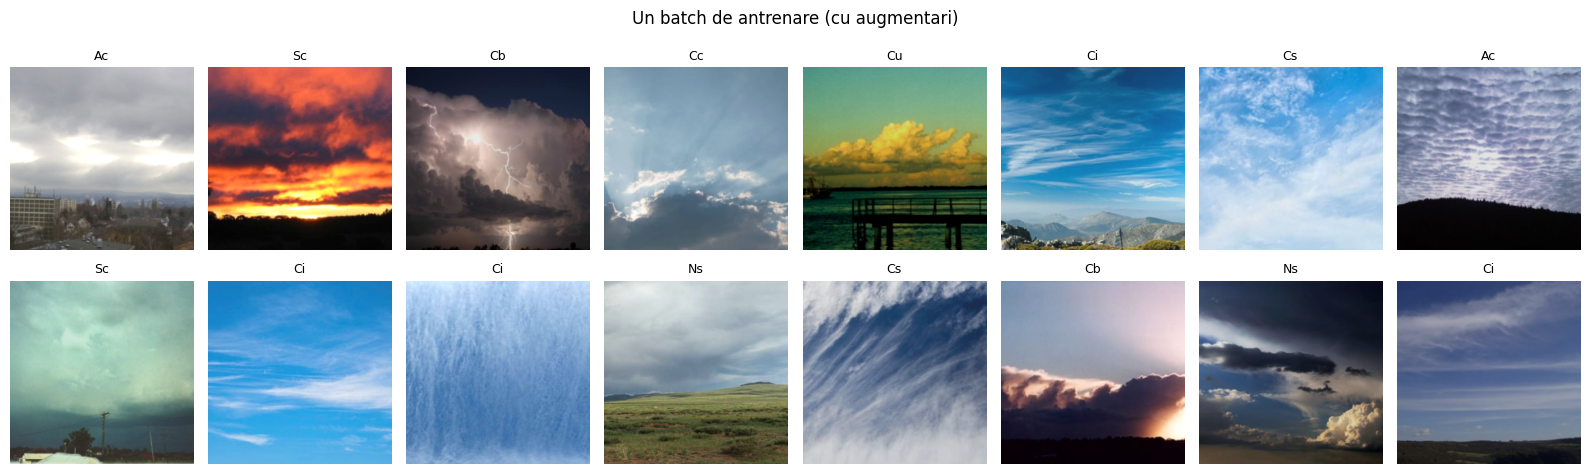

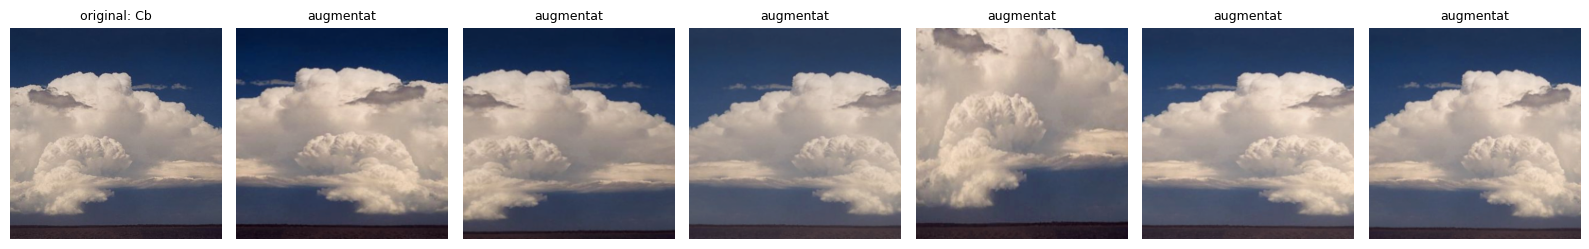

In [9]:
def denormalize(x):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


x, y = next(iter(loaders['train']))
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax, img, label in zip(axes.flat, x, y):
    ax.imshow(denormalize(img))
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis('off')
fig.suptitle('Un batch de antrenare (cu augmentari)')
plt.tight_layout()
plt.show()

idx = 0
original = Image.open(datasets_['train'].paths[idx]).convert('RGB')
fig, axes = plt.subplots(1, 7, figsize=(16, 2.8))
axes[0].imshow(original)
axes[0].set_title('original: ' + CLASSES[datasets_['train'].targets[idx]], fontsize=9)
for ax in axes[1:]:
    ax.imshow(denormalize(train_transform(original)))
    ax.set_title('augmentat', fontsize=9)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Rezumat
- `CCSNDataset` + `build_dataloaders` incarca setul CCSN si il pre-proceseaza (redimensionare la 224x224, normalizare ImageNet, augmentari doar pe train).
- Impartirea este stratificata 70 / 15 / 15 si este salvata in `splits/ccsn_splits.csv`, deci toate experimentele folosesc aceleasi imagini de test.
- Verificarile din sectiunea 6 confirma ca fiecare imagine este citita o singura data, in split-ul corect, cu forma si tipul asteptate.